# Initial payment EDA
Executed block outputs; full 10-million-row population.
Regenerate with `.venv/Scripts/python.exe analysis/run_initial_eda.py`.
To run interactively from this folder, set ROOT to the project directory before cell 1.


## 01 · Setup and provenance

All input rows are retained. Full-file aggregates, never the first-1,000 preview, drive comparisons. Account identifiers remain strings. Amount is USD; duration is seconds; UTC is not customer local time. Blank labels mean no recorded anomaly label. Definitions: case brief appendix pp. 3–4. Questions and untested theories: analysis/questions.md. Independent reviews: analysis/reviews/.

In [1]:
ROOT = str(__import__('pathlib').Path.cwd().parent if __import__('pathlib').Path.cwd().name == 'analysis' else __import__('pathlib').Path.cwd())

from pathlib import Path
from collections import Counter
from datetime import datetime, timezone
import hashlib, json, platform, sys, time
import pandas as pd
import numpy as np
root = Path(ROOT)
out = root / 'outputs/eda_initial'
out.mkdir(parents=True, exist_ok=True)
source = root / 'outputs/cleaned/payments_cleaned.csv.gz'
profile = json.loads((root / 'outputs/cleaned/profile.json').read_text())
manifest = {'started_utc': datetime.now(timezone.utc).isoformat(),
 'input': str(source), 'input_bytes': source.stat().st_size,
 'input_mtime_ns': source.stat().st_mtime_ns, 'python': sys.version,
 'pandas': pd.__version__, 'numpy': np.__version__,
 'script_sha256': hashlib.sha256((root/'analysis/run_initial_eda.py').read_bytes()).hexdigest(),
 'scope': 'full cleaned file; no exclusions; no deduplication',
 'definitions_source': 'case brief appendix pp. 3–4',
 'note': 'File identity uses size/mtime, not a content checksum; profile retained unchanged.'}
print(json.dumps(manifest, indent=2))
print('Historical profile limitation is stale: duration and B/C meanings ARE defined by appendix.')


{
  "started_utc": "2026-11-14T09:16:48.765840+00:00",
  "input": "C:\\Users\\yapka\\Documents\\UM\\Y1 SEM 1\\datathon\\outputs\\cleaned\\payments_cleaned.csv.gz",
  "input_bytes": 2050598614,
  "input_mtime_ns": 1794563110205336900,
  "python": "3.14.2 (tags/v3.14.2:df79316, Dec  5 2025, 17:18:21) [MSC v.1944 64 bit (AMD64)]",
  "pandas": "3.1.1",
  "numpy": "2.5.4",
  "script_sha256": "6156a8186c487ab9521024acac73ab3a7547dbdeb37e6b907b41cb0cc90dbf25",
  "scope": "full cleaned file; no exclusions; no deduplication",
  "definitions_source": "case brief appendix pp. 3\u20134",
  "note": "File identity uses size/mtime, not a content checksum; profile retained unchanged."
}
Historical profile limitation is stale: duration and B/C meanings ARE defined by appendix.


## 02 · Full-file scan

Question R1 (relationship/comparison): within each route type and continuity flag, does visible BIC entry count equal participant_count? Count entries matching [A-Z0-9]{8}; count literal ... separately; retain unknown tokens and repeated BICs. Difference = reported participants minus visible entries. Cross-tabulate all existing routing diagnostics before interpreting them. Month is a descriptive stability check, not a pre-registered holdout.

In [2]:

cols = ['source_record','epoch_seconds','bic8_path','participant_count','continuity_qflag',
 'transaction_type_code','quality_flags','currency_conversion_count','anomaly_type',
 'ordering_type','beneficiary_type','currency_code','usd_amount','total_duration',
 'ordering_bic8','beneficiary_bic8']
route = Counter(); monthly = Counter(); diagnostics = Counter(); labels = Counter()
party = Counter(); hours = Counter(); fx = Counter(); examples = []
rows = 0; minimum = None; maximum = None; bad_tokens = 0; quality_rows = 0
numeric = {c: {'count': 0, 'sum': 0.0, 'min': float('inf'), 'max': float('-inf')}
           for c in ['usd_amount','total_duration']}
started = time.monotonic()
for d in pd.read_csv(source, usecols=cols, dtype=str, keep_default_na=False, chunksize=100000):
    dates = pd.to_datetime(pd.to_numeric(d.epoch_seconds, errors='raise'), unit='s', utc=True)
    p = pd.to_numeric(d.participant_count, errors='raise').astype(int)
    paths = d.bic8_path.str.split(';')
    v = paths.map(lambda a: sum(bool(__import__('re').fullmatch('[A-Z0-9]{8}', t)) for t in a))
    gaps = paths.map(lambda a: a.count('...'))
    unknown = paths.str.len() - v - gaps
    unique = paths.map(lambda a: len({t for t in a if __import__('re').fullmatch('[A-Z0-9]{8}', t)}))
    x = pd.DataFrame({'continuity': d.continuity_qflag, 'route_type': d.transaction_type_code,
        'visible_entries': v, 'gap_entries': gaps, 'unknown_entries': unknown,
        'participant_count': p, 'distinct_visible_bics': unique, 'difference': p-v})
    route.update(x.value_counts(sort=False).to_dict())
    m = x[['continuity','route_type','difference']].copy()
    m['month_utc'] = dates.dt.strftime('%Y-%m')
    monthly.update(m.value_counts(sort=False).to_dict())
    base = ['continuity','route_type']
    for flag in ['path_participant_count_mismatch','path_ordering_endpoint_mismatch',
                 'path_beneficiary_endpoint_mismatch']:
        f = x[base].copy(); f['present'] = d.quality_flags.str.split(';').map(lambda a: flag in a)
        diagnostics.update({(flag,)+k: n for k,n in f.value_counts(sort=False).items()})
    labels.update(d.anomaly_type.value_counts().to_dict())
    party.update(d[['ordering_type','beneficiary_type']].value_counts().to_dict())
    h = pd.DataFrame({'hour_utc': dates.dt.hour, 'weekday_utc': dates.dt.dayofweek,
                      'ordering_type': d.ordering_type, 'beneficiary_type': d.beneficiary_type})
    hours.update(h.value_counts(sort=False).to_dict())
    f = x[base+['participant_count']].copy()
    f['fx_steps'] = pd.to_numeric(d.currency_conversion_count, errors='raise').astype(int)
    fx.update(f.value_counts(sort=False).to_dict())
    for c in numeric:
        a = pd.to_numeric(d[c], errors='raise')
        numeric[c]['count'] += len(a); numeric[c]['sum'] += float(a.sum())
        numeric[c]['min'] = min(numeric[c]['min'], float(a.min()))
        numeric[c]['max'] = max(numeric[c]['max'], float(a.max()))
    # Deterministic illustrative examples: first two per continuity/type/difference class.
    for key, ix in x.groupby(['continuity','route_type','difference'], sort=False).groups.items():
        have = sum(e['_class'] == list(key) for e in examples)
        for idx in list(ix)[:max(0,2-have)]:
            e = d.loc[idx,['source_record','bic8_path','participant_count','continuity_qflag',
                'transaction_type_code','ordering_bic8','beneficiary_bic8','quality_flags']].to_dict()
            e['_class'] = list(key); examples.append(e)
    bad_tokens += int(unknown.sum()); quality_rows += int(d.quality_flags.ne('').sum())
    rows += len(d)
    minimum = dates.min() if minimum is None else min(minimum,dates.min())
    maximum = dates.max() if maximum is None else max(maximum,dates.max())
    if rows % 1000000 == 0: print(f'{rows:,} rows scanned; {time.monotonic()-started:.1f}s')
print(f'Completed {rows:,} logical records; UTC range {minimum} to {maximum}')
print(f'Unknown path entries: {bad_tokens:,}; records with any existing diagnostic: {quality_rows:,}')


1,000,000 rows scanned; 31.7s
2,000,000 rows scanned; 63.1s
3,000,000 rows scanned; 96.3s
4,000,000 rows scanned; 127.6s
5,000,000 rows scanned; 157.9s
6,000,000 rows scanned; 184.3s
7,000,000 rows scanned; 211.8s
8,000,000 rows scanned; 238.8s
9,000,000 rows scanned; 266.3s
10,000,000 rows scanned; 293.3s
Completed 10,000,000 logical records; UTC range 2023-04-30 11:22:26+00:00 to 2023-07-31 09:56:01+00:00
Unknown path entries: 0; records with any existing diagnostic: 1,665,936


## 03 · Label coverage and population controls

Question A0 (composition): how many rows have each recorded label, including blank? Six observed nonblank labels versus five documented; CUSTOMER_RECALL has no supplied definition. This reconciles coverage, not the anomaly-generating mechanism. Numeric means are full-population floating-point summaries, not robust descriptions of typical amounts.

In [3]:

def save_counter(counter, names, filename):
    table = pd.DataFrame([list(k if isinstance(k,tuple) else (k,))+[int(n)] for k,n in counter.items()],
                         columns=names+['records']).sort_values(names).reset_index(drop=True)
    table.to_csv(out/filename,index=False)
    return table
label_table = save_counter(labels,['anomaly_type'],'labels.csv')
label_table['meaning'] = label_table.anomaly_type.map(lambda x: 'no recorded anomaly label' if x=='' else
    ('not defined in supplied appendix' if x=='CUSTOMER_RECALL' else 'defined in appendix'))
label_table['percent_all_rows'] = 100*label_table.records/rows
label_table.to_csv(out/'labels.csv',index=False)
print(label_table.to_string(index=False))
print('\nParty pair composition (not an inferred business rule):')
print(save_counter(party,['ordering_type','beneficiary_type'],'party_pairs.csv').to_string(index=False))
for c,s in numeric.items(): s['mean'] = s['sum']/s['count']
print('\nFull-population numeric controls:',json.dumps(numeric,indent=2))


            anomaly_type  records                          meaning  percent_all_rows
                          9992994        no recorded anomaly label          99.92994
ACCOUNT_REPLACEMENT_SCAM      649              defined in appendix           0.00649
                CEO_SCAM      945              defined in appendix           0.00945
         CUSTOMER_RECALL      317 not defined in supplied appendix           0.00317
       DUPLICATE_PAYMENT      679              defined in appendix           0.00679
      FAT_FINGER_MISTAKE     1940              defined in appendix           0.01940
            ROMANCE_SCAM     2476              defined in appendix           0.02476

Party pair composition (not an inferred business rule):
ordering_type beneficiary_type  records
            B                B  2270945
            B                C  5603692
            C                B   610605
            C                C  1514758

Full-population numeric controls: {
  "usd_amount": {
    "cou

## 04 · Routing cross-tabs and stability

Report denominators explicitly. Tables retain sparse and disagreeing cells. A match describes an observed encoding relationship; it cannot establish economic causality or recover the hidden institutions. Endpoint diagnostics are checked separately from participant discrepancies.

In [4]:

routes = save_counter(route,['continuity','route_type','visible_entries','gap_entries','unknown_entries',
    'participant_count','distinct_visible_bics','difference'],'route_counts.csv')
months = save_counter(monthly,['continuity','route_type','difference','month_utc'],'route_month.csv')
flags = save_counter(diagnostics,['diagnostic','continuity','route_type','present'],'route_diagnostics.csv')
save_counter(hours,['hour_utc','weekday_utc','ordering_type','beneficiary_type'],'time_composition.csv')
save_counter(fx,['continuity','route_type','participant_count','fx_steps'],'routing_fx.csv')
summary = routes.assign(equal_records=lambda t: t.records*t.difference.eq(0),
    gap_records=lambda t: t.records*t.gap_entries.gt(0),
    repeated_bic_records=lambda t: t.records*t.visible_entries.ne(t.distinct_visible_bics),
    reported_minus_visible_sum=lambda t: t.records*t.difference).groupby(['continuity','route_type']).agg(
    records=('records','sum'), equal_records=('equal_records','sum'),
    gap_records=('gap_records','sum'), repeated_bic_records=('repeated_bic_records','sum'),
    reported_minus_visible_sum=('reported_minus_visible_sum','sum')).reset_index()
summary['equal_percent'] = 100*summary.equal_records/summary.records
summary['mean_reported_minus_visible'] = summary.reported_minus_visible_sum/summary.records
summary.to_csv(out/'route_summary.csv',index=False)
print(summary.to_string(index=False))
print('\nAll observed participant-minus-visible differences:')
print(routes.groupby(['continuity','difference']).records.sum().to_string())
print('\nDiagnostics by continuity/type (both present and absent):')
print(flags.to_string(index=False))
print('\nMonthly comparison:')
print(months.to_string(index=False))
pd.DataFrame([{k:v for k,v in e.items() if k!='_class'} for e in examples]).to_csv(out/'route_examples.csv',index=False)


continuity route_type  records  equal_records  gap_records  repeated_bic_records  reported_minus_visible_sum  equal_percent  mean_reported_minus_visible
         N    Covered    51262          51262        51262                  1827                           0          100.0                          0.0
         N     Direct   315266         315266       315266                     0                           0          100.0                          0.0
         N   Indirect   400676         400676       400676                  8176                           0          100.0                          0.0
         Y    Covered   364700         364700            0                  9566                           0          100.0                          0.0
         Y     Direct  6008014        6008014            0                     6                           0          100.0                          0.0
         Y   Indirect  2860082        2860082            0                 39616  

## 05 · Reconciliation and completion

Assertions validate counts against the existing full profile. No corrections are written into the cleaned data or historical profile. Separate metadata records the appendix corrections. See analysis/progress.md for reviewed wording and remaining tests; this notebook intentionally stops at initial EDA.

In [5]:

assert rows == profile['records'] == 10000000
assert dict(labels) == profile['category_counts']['anomaly_type']
assert labels['CUSTOMER_RECALL'] == 317
assert quality_rows == profile['flagged_records']
assert routes.records.sum() == months.records.sum() == rows
assert sum(party.values()) == sum(hours.values()) == sum(fx.values()) == rows
for flag in flags.diagnostic.unique():
    a = flags[flags.diagnostic.eq(flag)]
    assert a.records.sum() == rows
    assert int(a.loc[a.present,'records'].sum()) == profile['issue_counts'][flag]
manifest.update({'records': rows, 'date_min_utc':str(minimum),'date_max_utc':str(maximum),
 'elapsed_scan_seconds': round(time.monotonic()-started,2), 'all_controls_passed':True,
 'completed_utc': datetime.now(timezone.utc).isoformat(),
 'definition_corrections': {'total_duration':'seconds','B':'business','C':'consumer',
 'usd_amount':'normalized USD','tokens':'derived text patterns',
 'gap':'literal ... is not a visible institution','blank_label':'no recorded anomaly label'}})
(out/'manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
print('PASS: row counts, labels, diagnostics and all aggregate denominators reconcile with full profile.')
print('Saved tables:', ', '.join(p.name for p in sorted(out.glob('*.csv'))))


PASS: row counts, labels, diagnostics and all aggregate denominators reconcile with full profile.
Saved tables: labels.csv, party_pairs.csv, route_counts.csv, route_diagnostics.csv, route_examples.csv, route_month.csv, route_summary.csv, routing_fx.csv, time_composition.csv


## 06 · Initial charts
R1 is an observed encoding relationship, not proof of the hidden generator. A0 is label coverage, not an anomaly mechanism. Review: `analysis/progress.md`.

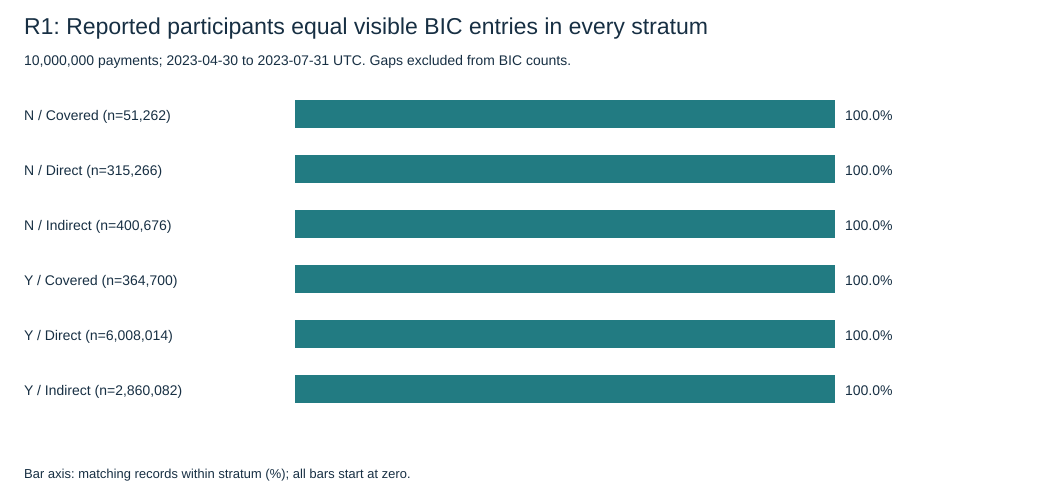

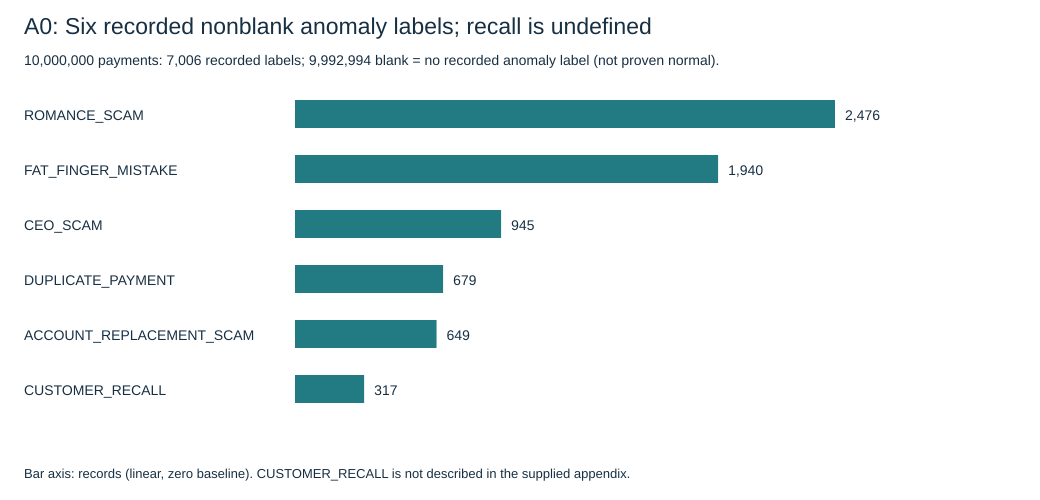

In [6]:

from pathlib import Path
from html import escape
import pandas as pd
root = Path(ROOT)
out = root/'outputs/eda_initial'
summary = pd.read_csv(out/'route_summary.csv', keep_default_na=False)
labels = pd.read_csv(out/'labels.csv', keep_default_na=False)
import json
run = json.loads((out/'manifest.json').read_text())
def bars(title, subtitle, names, values, axis_note, path, formatter):
    width, height = 1040, 170+len(names)*55
    maximum = max(values) or 1
    parts = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">',
        '<rect width="100%" height="100%" fill="white"/>',
        '<g font-family="Arial, sans-serif" fill="#172f43">',
        f'<text x="24" y="34" font-size="23">{escape(title)}</text>',
        f'<text x="24" y="65" font-size="14">{escape(subtitle)}</text>']
    for i,(name,value) in enumerate(zip(names,values)):
        y=100+i*55
        parts += [f'<text x="24" y="{y+20}" font-size="14">{escape(str(name))}</text>',
            f'<rect x="295" y="{y}" width="{540*value/maximum:.3f}" height="28" fill="#227b82"/>',
            f'<text x="{305+540*value/maximum:.3f}" y="{y+20}" font-size="14">{escape(formatter(value))}</text>']
    parts += [f'<text x="24" y="{height-22}" font-size="13">{escape(axis_note)}</text>','</g></svg>']
    path.write_text('\n'.join(parts),encoding='utf-8')
    return '\n'.join(parts)
svg_route = bars('R1: Reported participants equal visible BIC entries in every stratum',
    f"10,000,000 payments; {run['date_min_utc'][:10]} to {run['date_max_utc'][:10]} UTC. Gaps excluded from BIC counts.",
    [f'{r.continuity} / {r.route_type} (n={r.records:,})' for r in summary.itertuples()],
    summary.equal_percent.tolist(),'Bar axis: matching records within stratum (%); all bars start at zero.',
    out/'R1_visible_participants.svg',lambda v:f'{v:.1f}%')
nonblank = labels[labels.anomaly_type.ne('')].sort_values('records',ascending=False)
svg_labels = bars('A0: Six recorded nonblank anomaly labels; recall is undefined',
    '10,000,000 payments: 7,006 recorded labels; 9,992,994 blank = no recorded anomaly label (not proven normal).',
    nonblank.anomaly_type.tolist(),nonblank.records.tolist(),
    'Bar axis: records (linear, zero baseline). CUSTOMER_RECALL is not described in the supplied appendix.',
    out/'A0_label_counts.svg',lambda v:f'{int(v):,}')
print('Saved R1_visible_participants.svg and A0_label_counts.svg; counts come from executed full-file aggregates.')


## 07 · Independent review verification
Exact comparison of lead/A/B aggregates, monthly and July splits, endpoint diagnostics and labels. Initial conclusions and exchanged debate: `analysis/reviews/`; final wording: `analysis/progress.md`.

In [7]:
import subprocess, sys
result = subprocess.run([sys.executable, str(root/'analysis/verify_reviews.py')],
                        cwd=root, capture_output=True, text=True, check=True)
print(result.stdout)


{
  "status": "PASS",
  "population": 10000000,
  "checks": [
    "A vs B vs lead exact joint route aggregates",
    "A vs lead exact monthly aggregates",
    "B vs lead pre-July/July aggregates",
    "B vs lead endpoint diagnostics by flag and route",
    "A vs B vs lead vs original profile label census"
  ],
  "participant_visible_equal": 10000000,
  "repeated_bic_rows": 59191,
  "gap_flag_disagreements": 0,
  "limits": [
    "Descriptive stability checks; discovery used full file, no untouched holdout.",
    "Cannot identify hidden banks, generator causal order, recall mechanism, or economic intent."
  ]
}

